In [191]:
import sys
import os
from typing import NamedTuple
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.decomposition import PCA
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold
import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), '../src'))
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../'))
from utils import plot_utils
from utils import train_utils
from models import bom
from models import hgm

In [192]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/models/hgm.py'>

In [193]:
dims = 2

file_id = 19

In [194]:
# read

path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')
(filename,
 traces,
 continuous_behaviors,
 discrete_states, eigenworms,
 kymographs) = read_utils.get_data(path, file_id)

# clear nan values
mask = eigenworms.notna().all(axis=1)

traces = traces[mask]
#continuous_behaviors = continuous_behaviors[mask]
eigenworms = eigenworms[mask]
discrete_states = discrete_states[mask]

#kymographs = kymographs[mask]

# naive ID unknown neurons
traces.columns = pd.Index([
	f'{file_id:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces.columns, traces.columns == ''))
])

In [195]:
selection_n = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',	# paper
			   'RMDDR', 'SMDDR', 'SMDDL',				# C
			   'AVAR', 'AVAL',							# M
			   'ALA', 'AWBR']							# O
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

selection_n = [label for label in selection_n if label in traces.columns]
# discrete_states = [ds[selection_bhl] for ds in discrete_states]

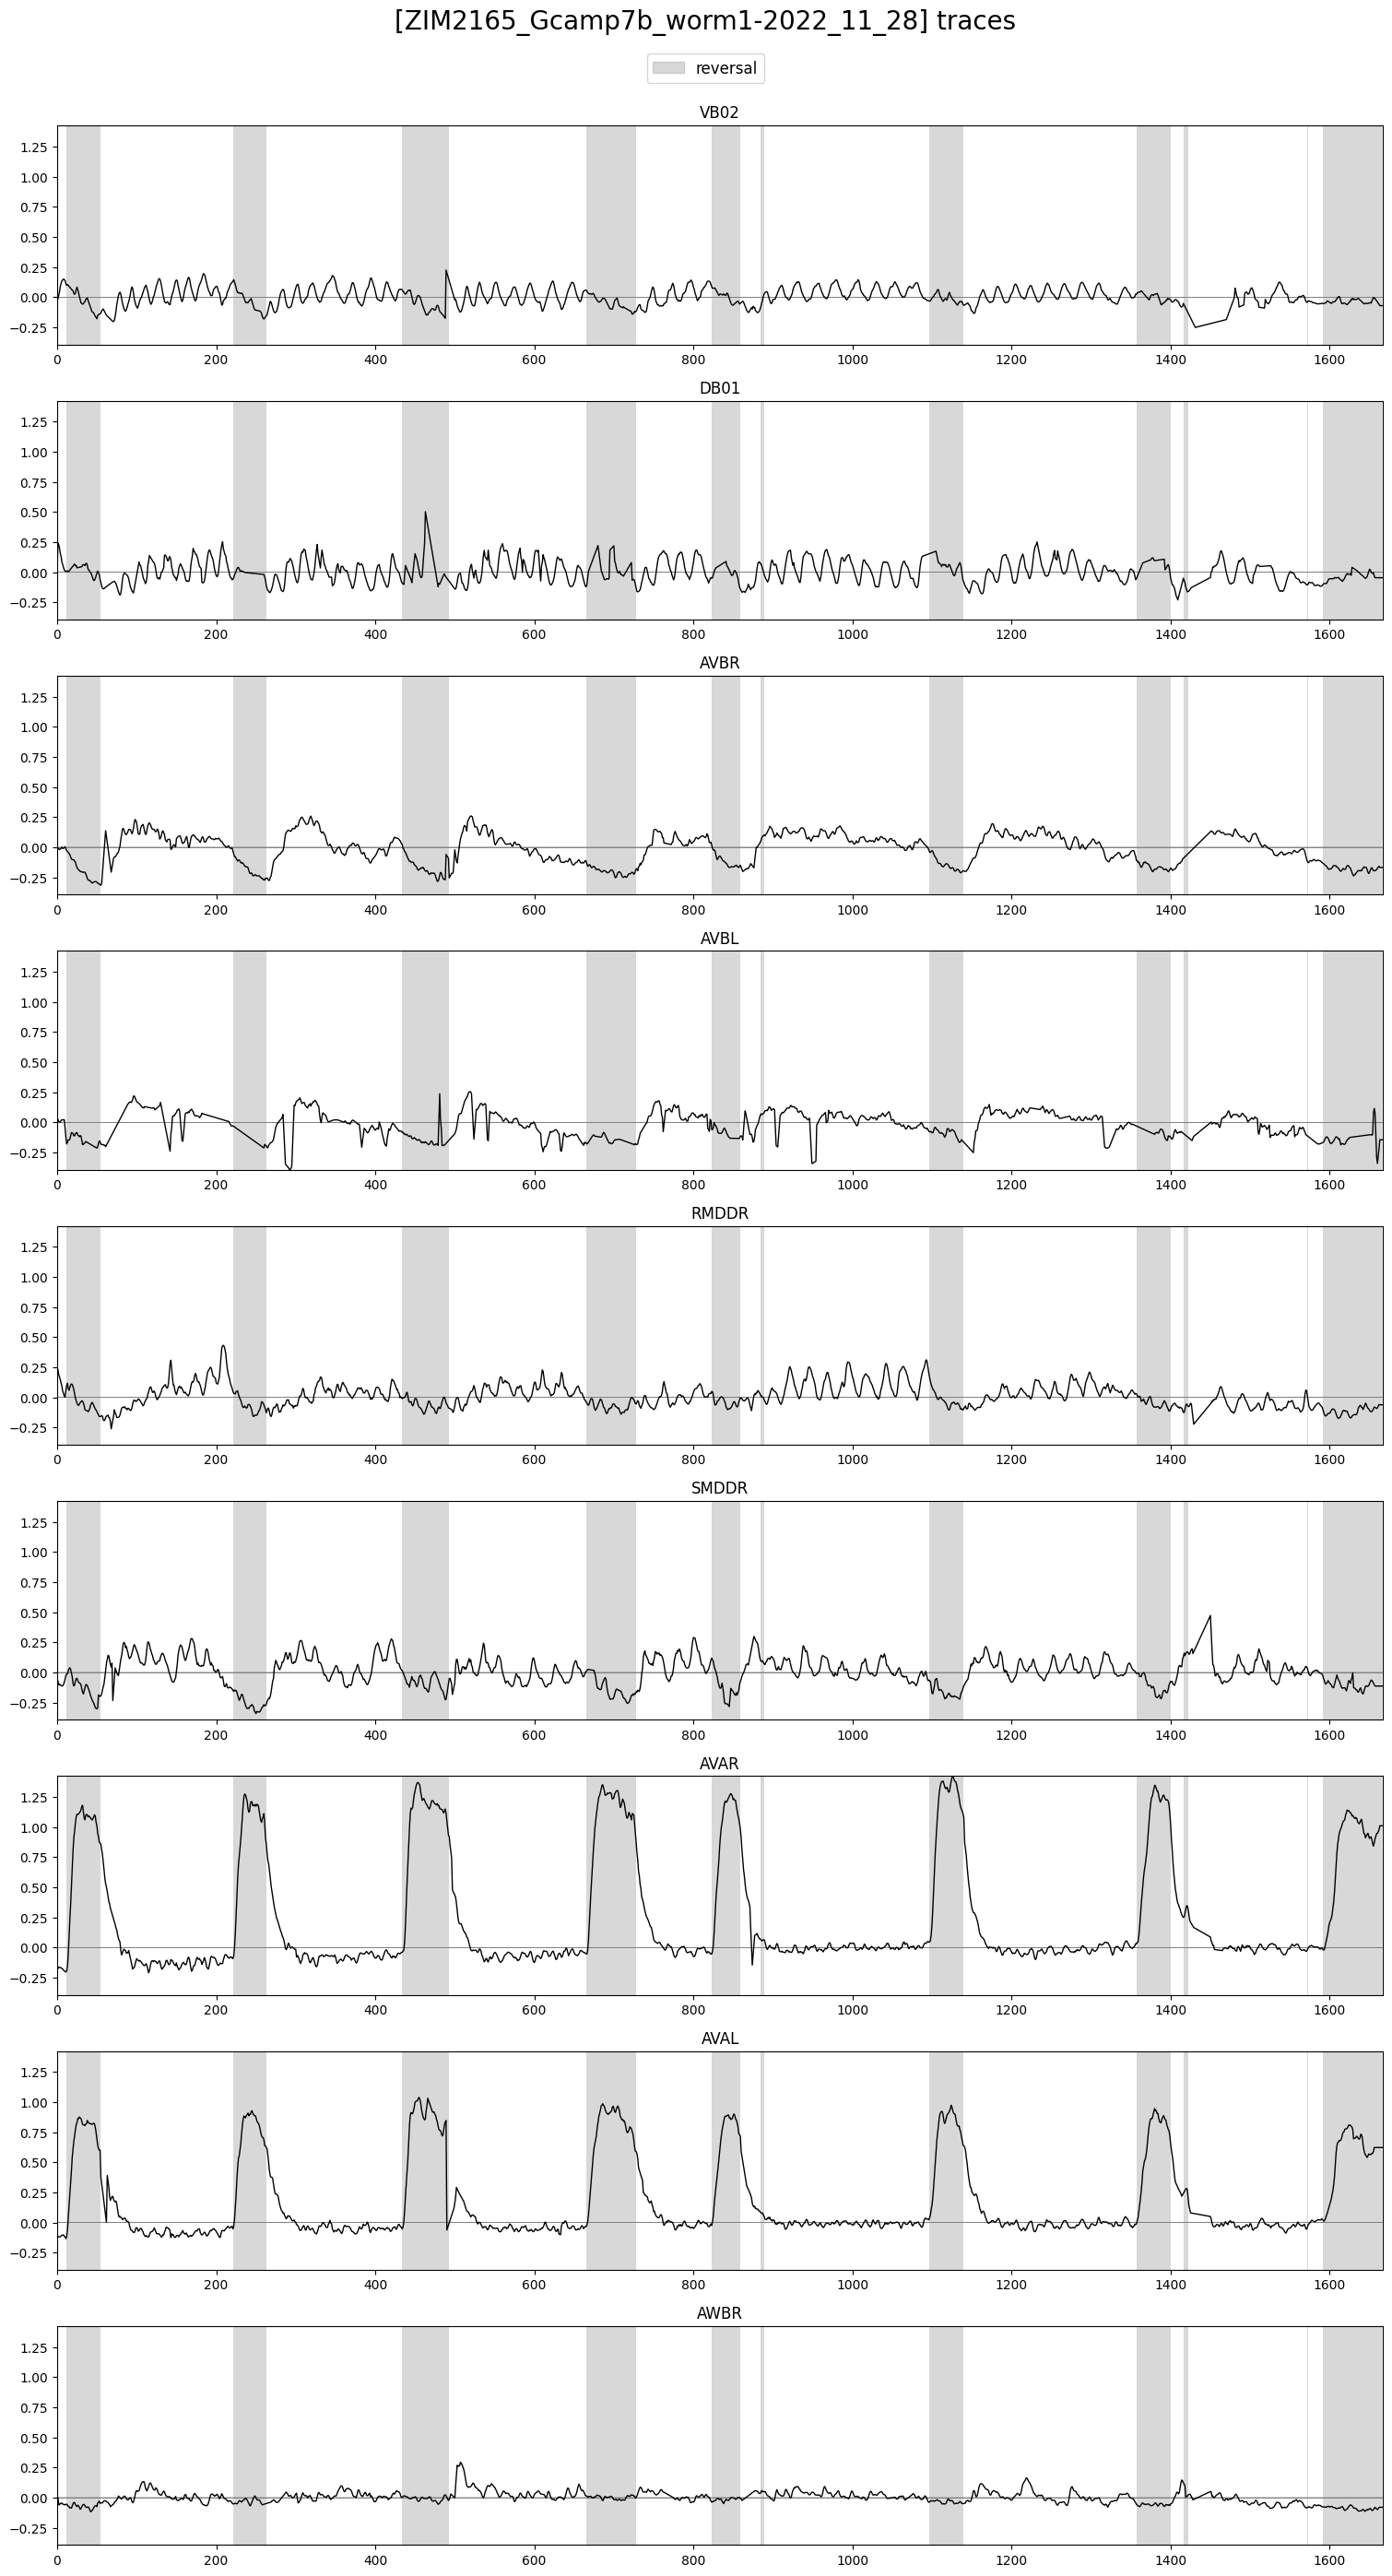

In [196]:
plot_utils.plot_traces(traces[selection_n],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] traces', ylimits=None)

# sklearn PCA

In [197]:
X = traces.values

In [198]:
pca = PCA(n_components=dims)
pca.fit(X)
X_l_h = pca.transform(X)
X_rec_h = pca.inverse_transform(X_l_h)

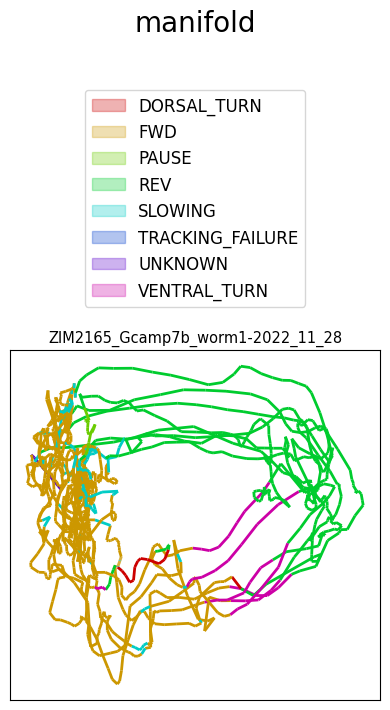

In [199]:
X_l_h_df = pd.DataFrame(data=X_l_h, columns=[f'PC{i}' for i in range(dims)])

if dims > 1:
	plot_utils.plot_manifolds([filename],
							  [X_l_h_df],
							  [discrete_states],
							  None, None,
							  title='manifold', top_space=3.5,
							  save_path=None)

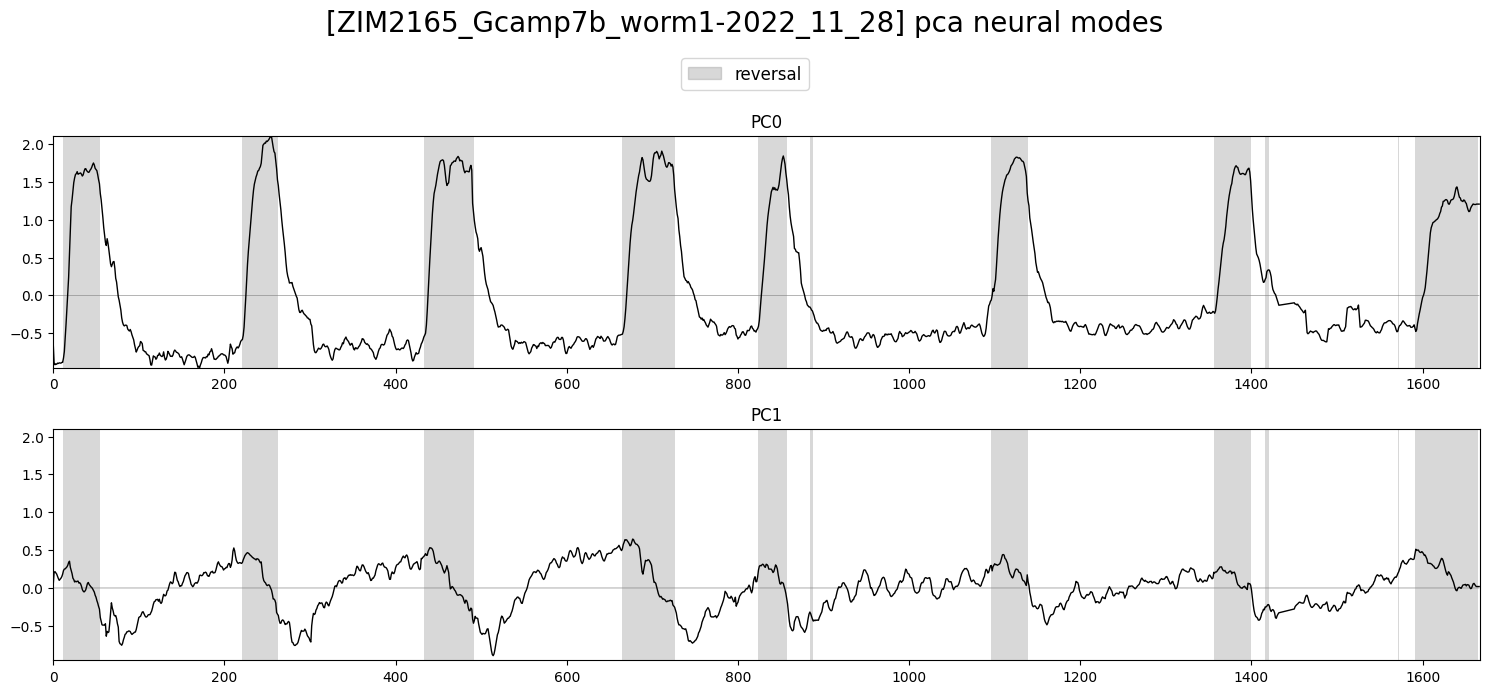

In [200]:
plot_utils.plot_traces([X_l_h_df],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] pca neural modes', ylimits=None)

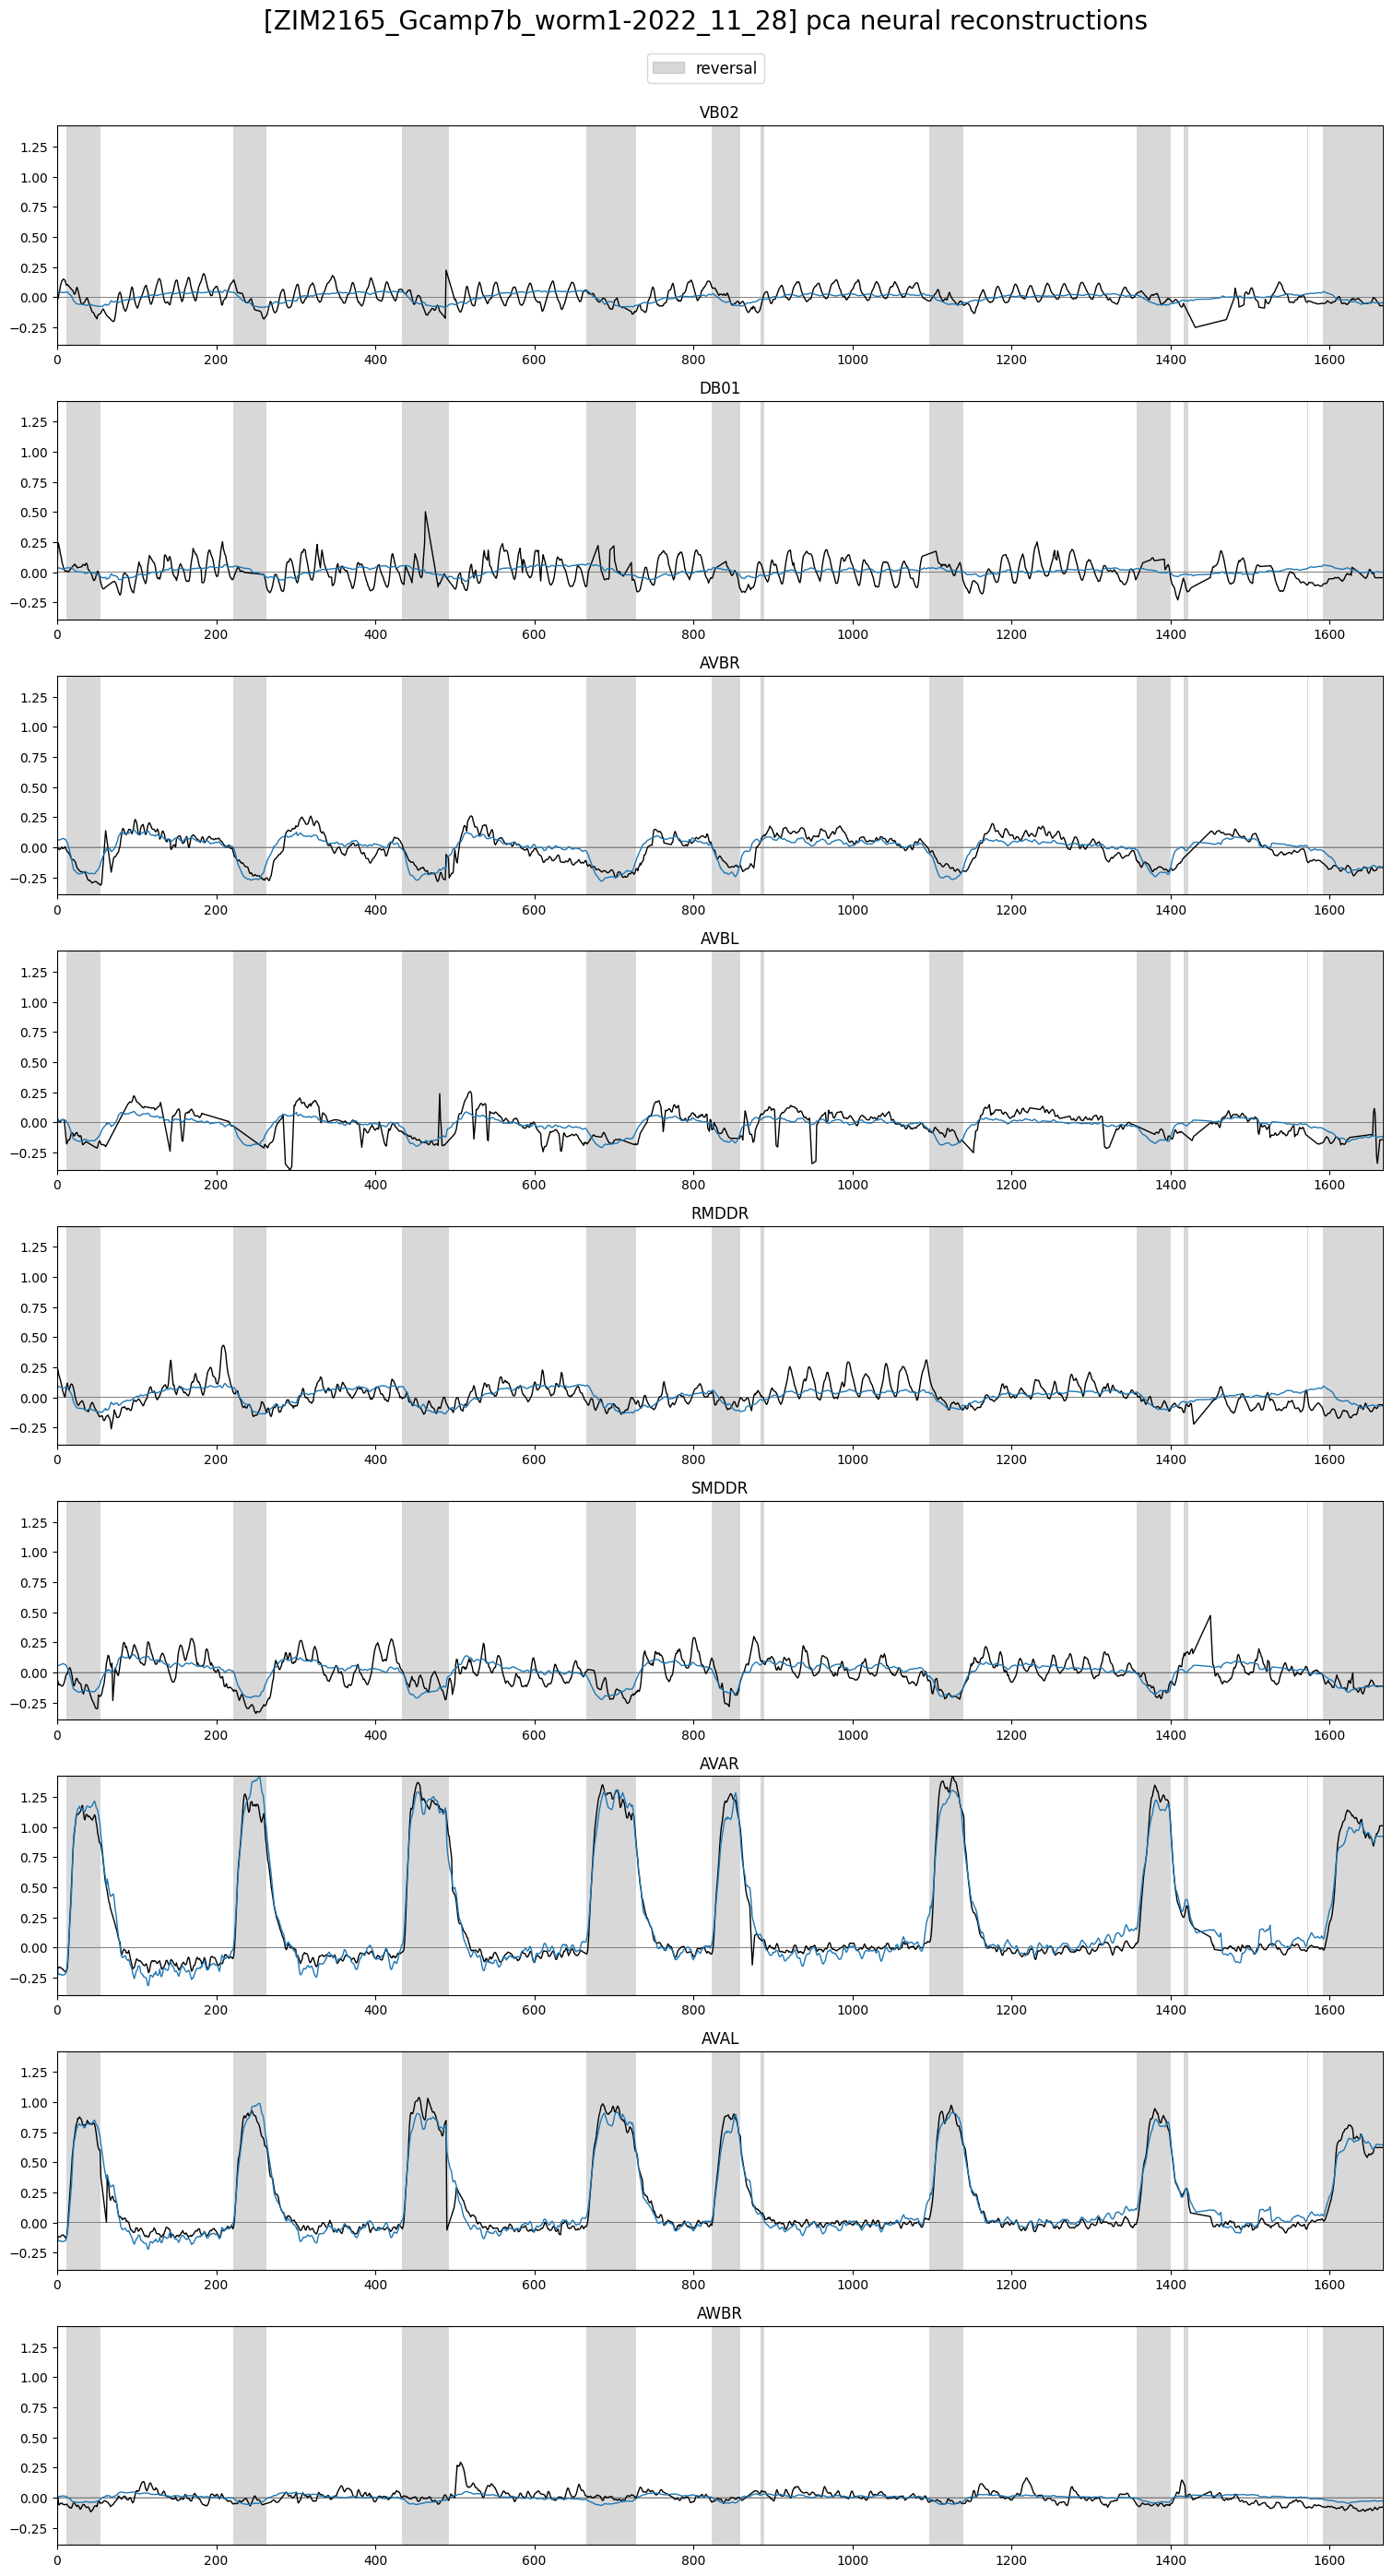

In [201]:
X_rec_h_df = pd.DataFrame(data=X_rec_h, columns=traces.columns)

plot_utils.plot_traces([traces[selection_n], X_rec_h_df[selection_n]],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] pca neural reconstructions', ylimits=None)

# soft CCA

In [202]:
def init_params(N, seeds, shape_U):
	return {
		'prep': {
			'N': {
				'mean': N.mean(axis=0),
				'std': jnp.where((N_std := jnp.std(N, axis=0)) == 0.0, 1.0, N_std),
			},
		},
		'model': {
			'U': 1E-5 * jax.random.normal(seeds[0], shape_U),
		}
	}


# @jax.jit
# def orthogonalize_qr(A):
# 	Q, R = jnp.linalg.qr(A)
# 	return Q * jnp.diag(R)  # also fixes sign ambiguity for a deterministic mapping


@jax.jit
def orthonormalize_qr(A):
	Q, R = jnp.linalg.qr(A)
	signs = jnp.sign(jnp.diag(R))  # fix sign ambiguity for a deterministic mapping
	return Q * jnp.where(signs == 0, 1.0, signs)


@jax.jit
def get_reconstruction_matrix(X, Y, U):
	# reconstruct Y (target) using X (predictor)

	# return jnp.linalg.inv(X.T @ X) @ X.T @ Y
	#
	# XTX = X.T @ X
	# lam = 1E2 * jnp.finfo(XTX.dtype).eps * jnp.maximum(jnp.trace(XTX) / XTX.shape[0], 1.0)
	# return jnp.linalg.solve(XTX + lam * jnp.eye(X.shape[1], dtype=X.dtype), X.T @ Y)

	return jnp.linalg.lstsq(X, Y)[0]
	# return jnp.linalg.pinv(U)
	# return U.T



@jax.jit
def predict(params, N):
	prep_n = jax.lax.stop_gradient(params['prep']['N'])
	N_mean, N_std = prep_n['mean'], prep_n['std']
	U = params['model']['U']

	# UQ = U
	UQ = orthonormalize_qr(U)

	N_zs = (N - N_mean) / N_std

	N_man = N_zs @ UQ

	N_zs_rec = N_man @ get_reconstruction_matrix(N_man, N_zs, UQ)
	N_rec = N_zs_rec * N_std + N_mean

	return N_man, N_rec


def loss_fn(params, N):
	N_man, N_rec = predict(params, N)
	man_loss = jnp.sum((N - N_rec) ** 2)  # ^p?
	return man_loss

loss_and_grads = jax.jit(jax.value_and_grad(loss_fn, has_aux=False))


def update(opt_update, opt_state, params, N):
	loss, grads = loss_and_grads(params, N)
	params_updates, opt_state = opt_update(grads, opt_state, params)
	params_new = optax.apply_updates(params, params_updates)
	return opt_state, params_new, loss

update = jax.jit(update, static_argnums=(0,))

In [203]:
def train(N, hyperparams):
	max_epochs = hyperparams['max_epochs']
	n_dimensions = hyperparams['dimensions']
	learning_rate = hyperparams['learning_rate']

	n_neurons = N.shape[1]

	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1)

	params = init_params(N, seeds, (n_neurons, n_dimensions))
	optimizer = optax.adam(learning_rate)
	optimizer = optax.masked(optimizer, {'prep': False, 'model': True})
	opt_state = optimizer.init(params)

	losses_train = []
	for epoch in range(max_epochs):
		opt_state, params, loss_train = update(optimizer.update, opt_state, params, N)
		losses_train.append(loss_train)

	return params, losses_train

In [204]:
hyperparameters = {
	'max_epochs': 20000,
	'learning_rate': 1E-1,
	'dimensions': dims
}
params, losses_train = train(X, hyperparameters)
X_l_s, X_rec_s = predict(params, X)

# corr_n = np.array(norming(X_l_s).T @ norming(Y_l_s) / norming(X_l_s).shape[0])

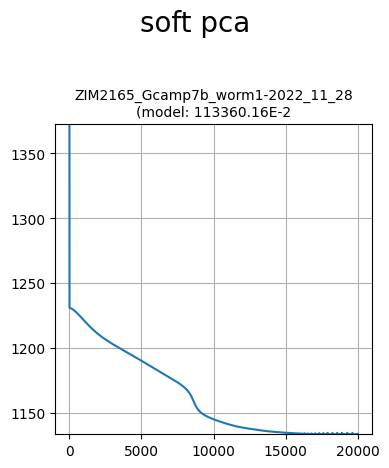

In [205]:
losses = np.array(losses_train)

plot_utils.plot_loss(filename,
					 losses,
					 title='soft pca', ylimits=0.2, plots_per_row=1)

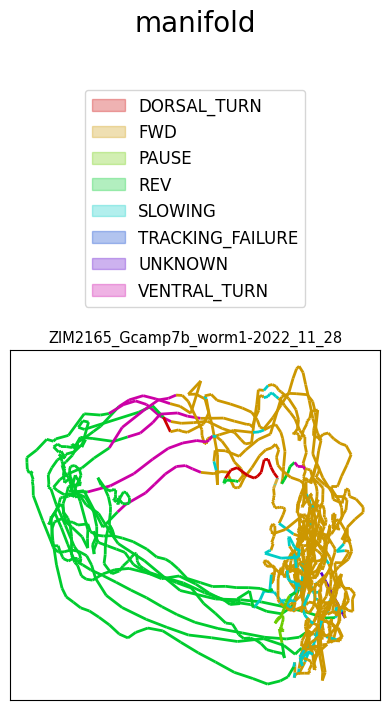

In [206]:
X_l_s_df = pd.DataFrame(data=X_l_s, columns=[f'PC{i}' for i in range(dims)])

if dims > 1:
	plot_utils.plot_manifolds([filename],
							  [X_l_s_df],
							  [discrete_states],
							  None, None,
							  title='manifold', top_space=3.5,
							  save_path=None)

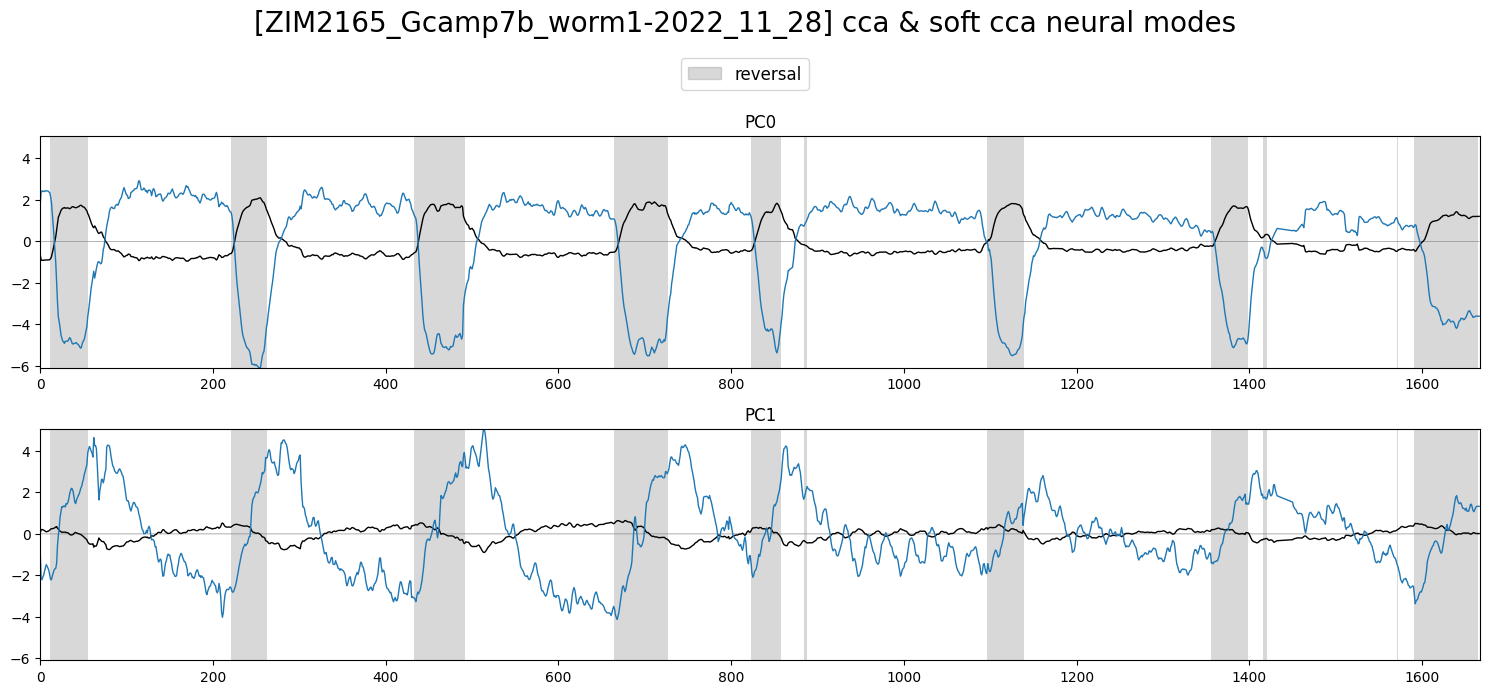

In [207]:
plot_utils.plot_traces([X_l_h_df, X_l_s_df],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] pca & soft pca neural modes', ylimits=None)

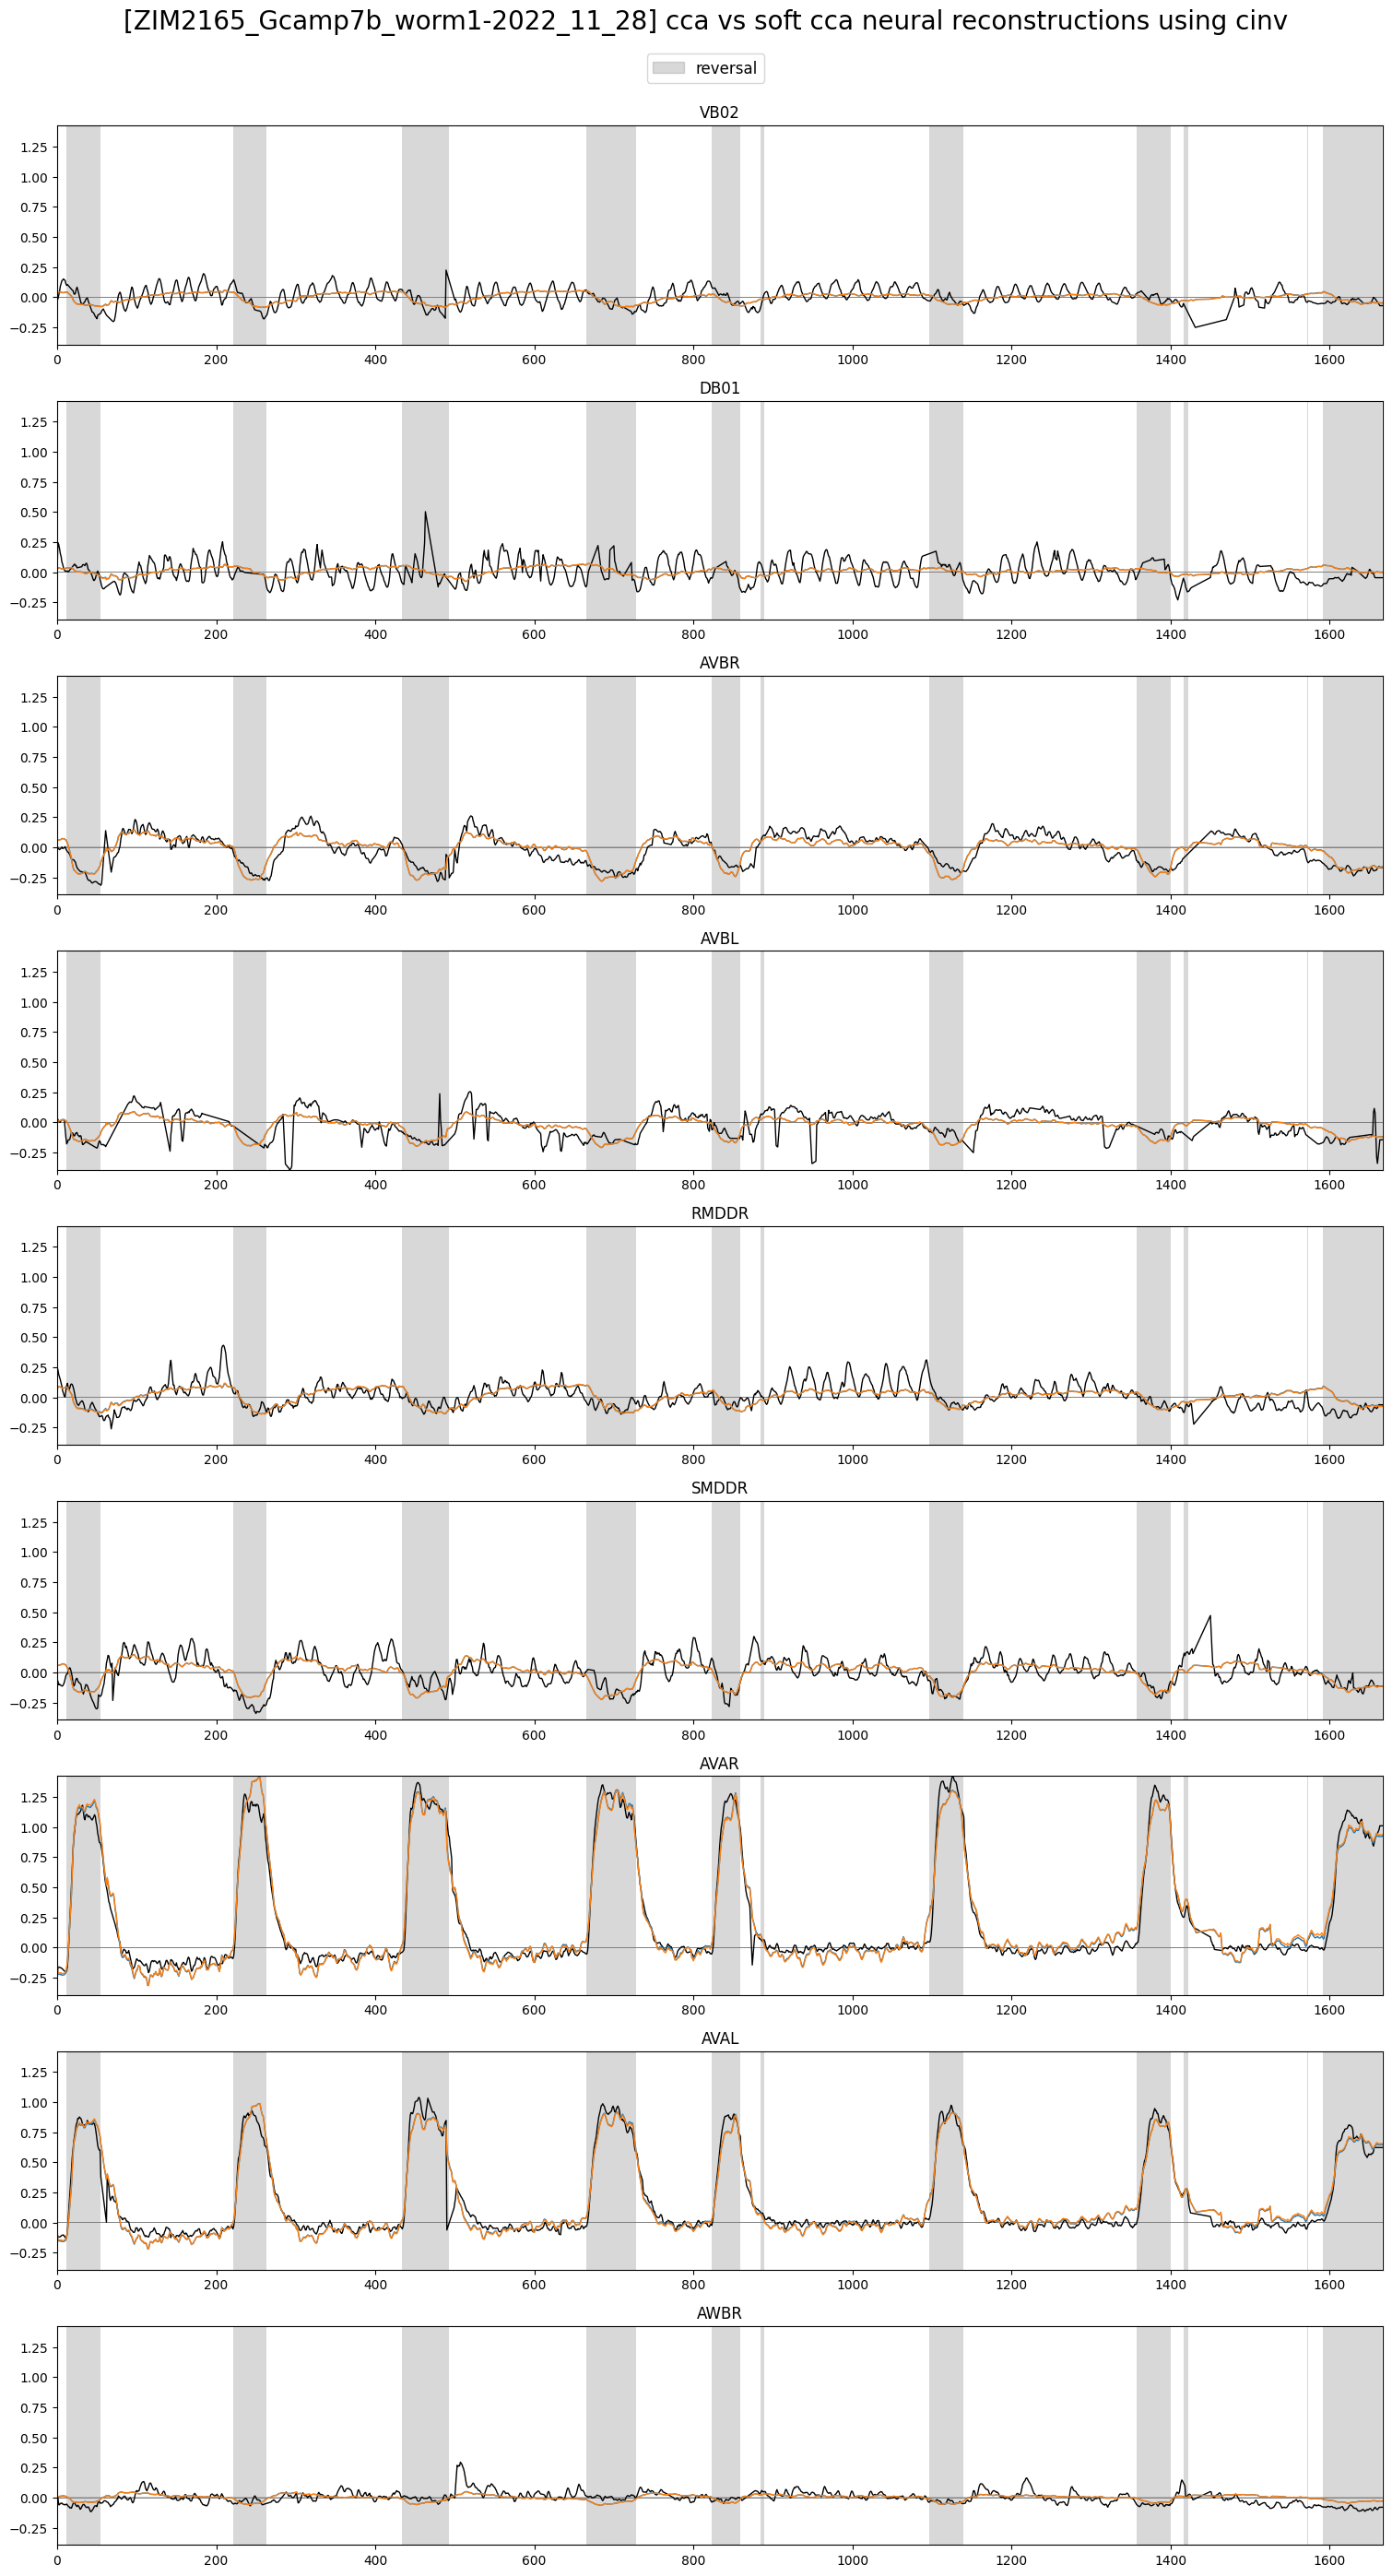

In [208]:
X_rec_s_df = pd.DataFrame(data=X_rec_s, columns=traces.columns)

plot_utils.plot_traces([traces[selection_n], X_rec_h_df[selection_n], X_rec_s_df[selection_n]],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] pca vs soft pca neural reconstructions using cinv', ylimits=None)

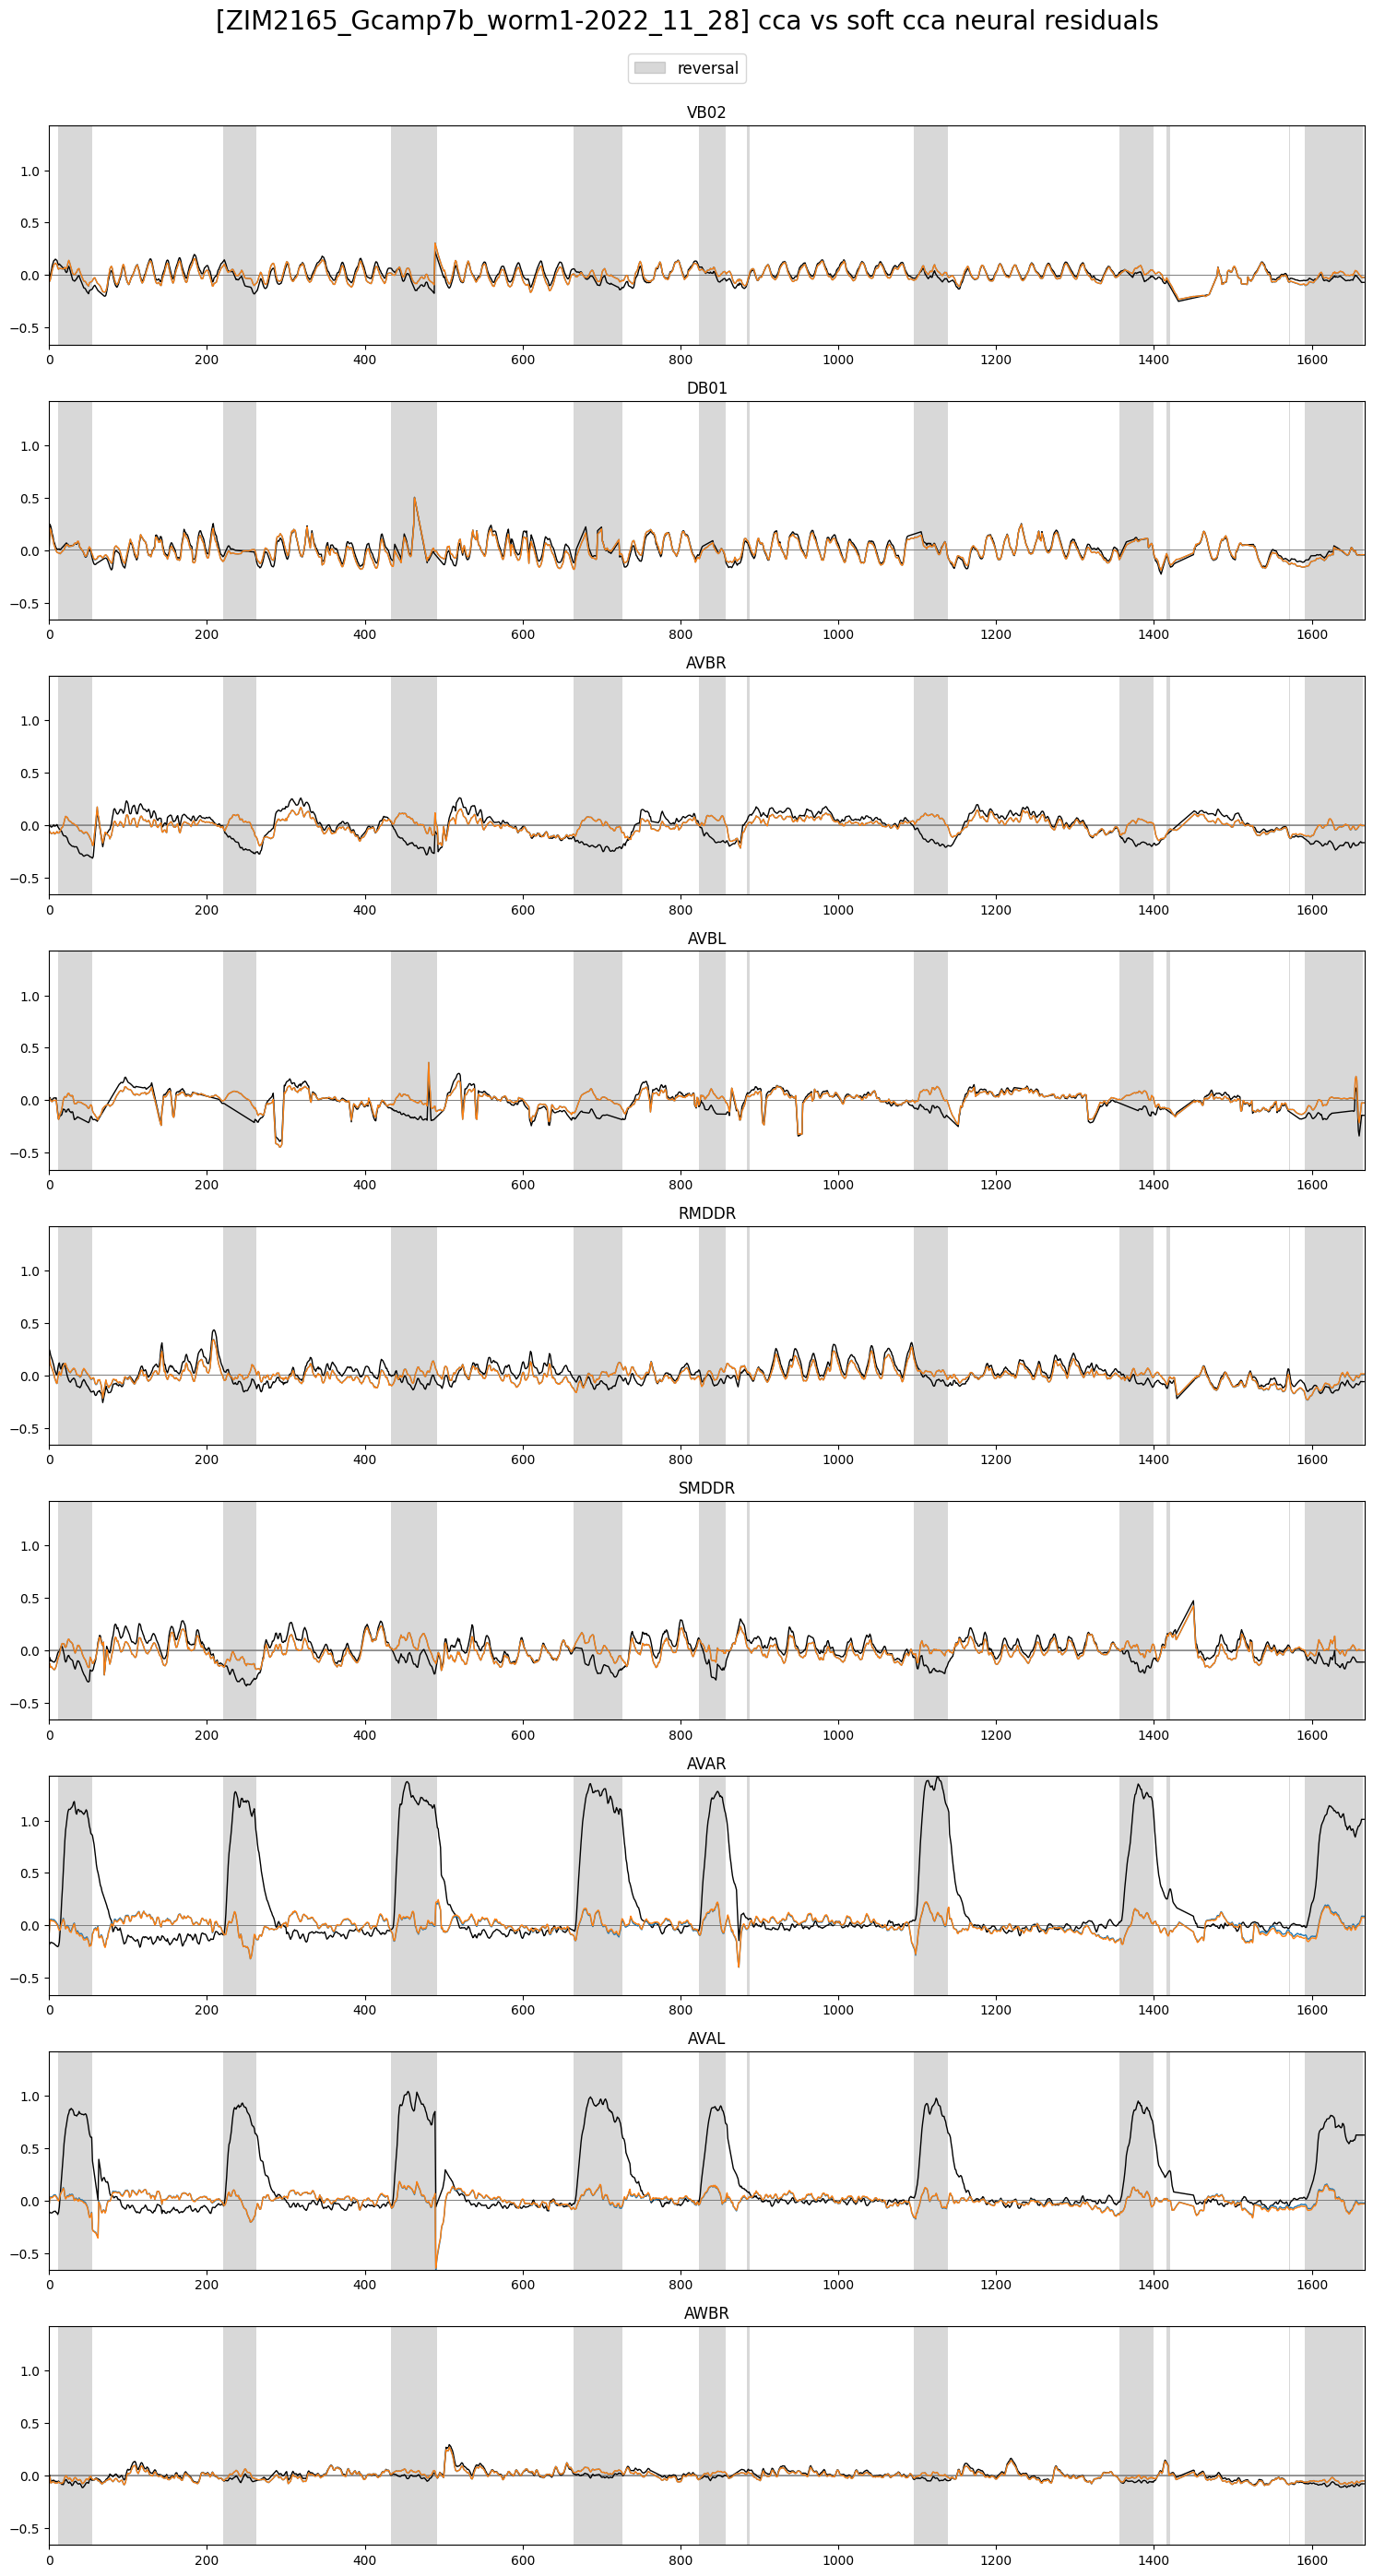

In [209]:
X_res_h_df = pd.DataFrame(data=X - X_rec_h, columns=traces.columns)
X_res_s_df = pd.DataFrame(data=X - X_rec_s, columns=traces.columns)

plot_utils.plot_traces([traces[selection_n], X_res_h_df[selection_n], X_res_s_df[selection_n]],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] pca vs soft pca neural residuals', ylimits=None)

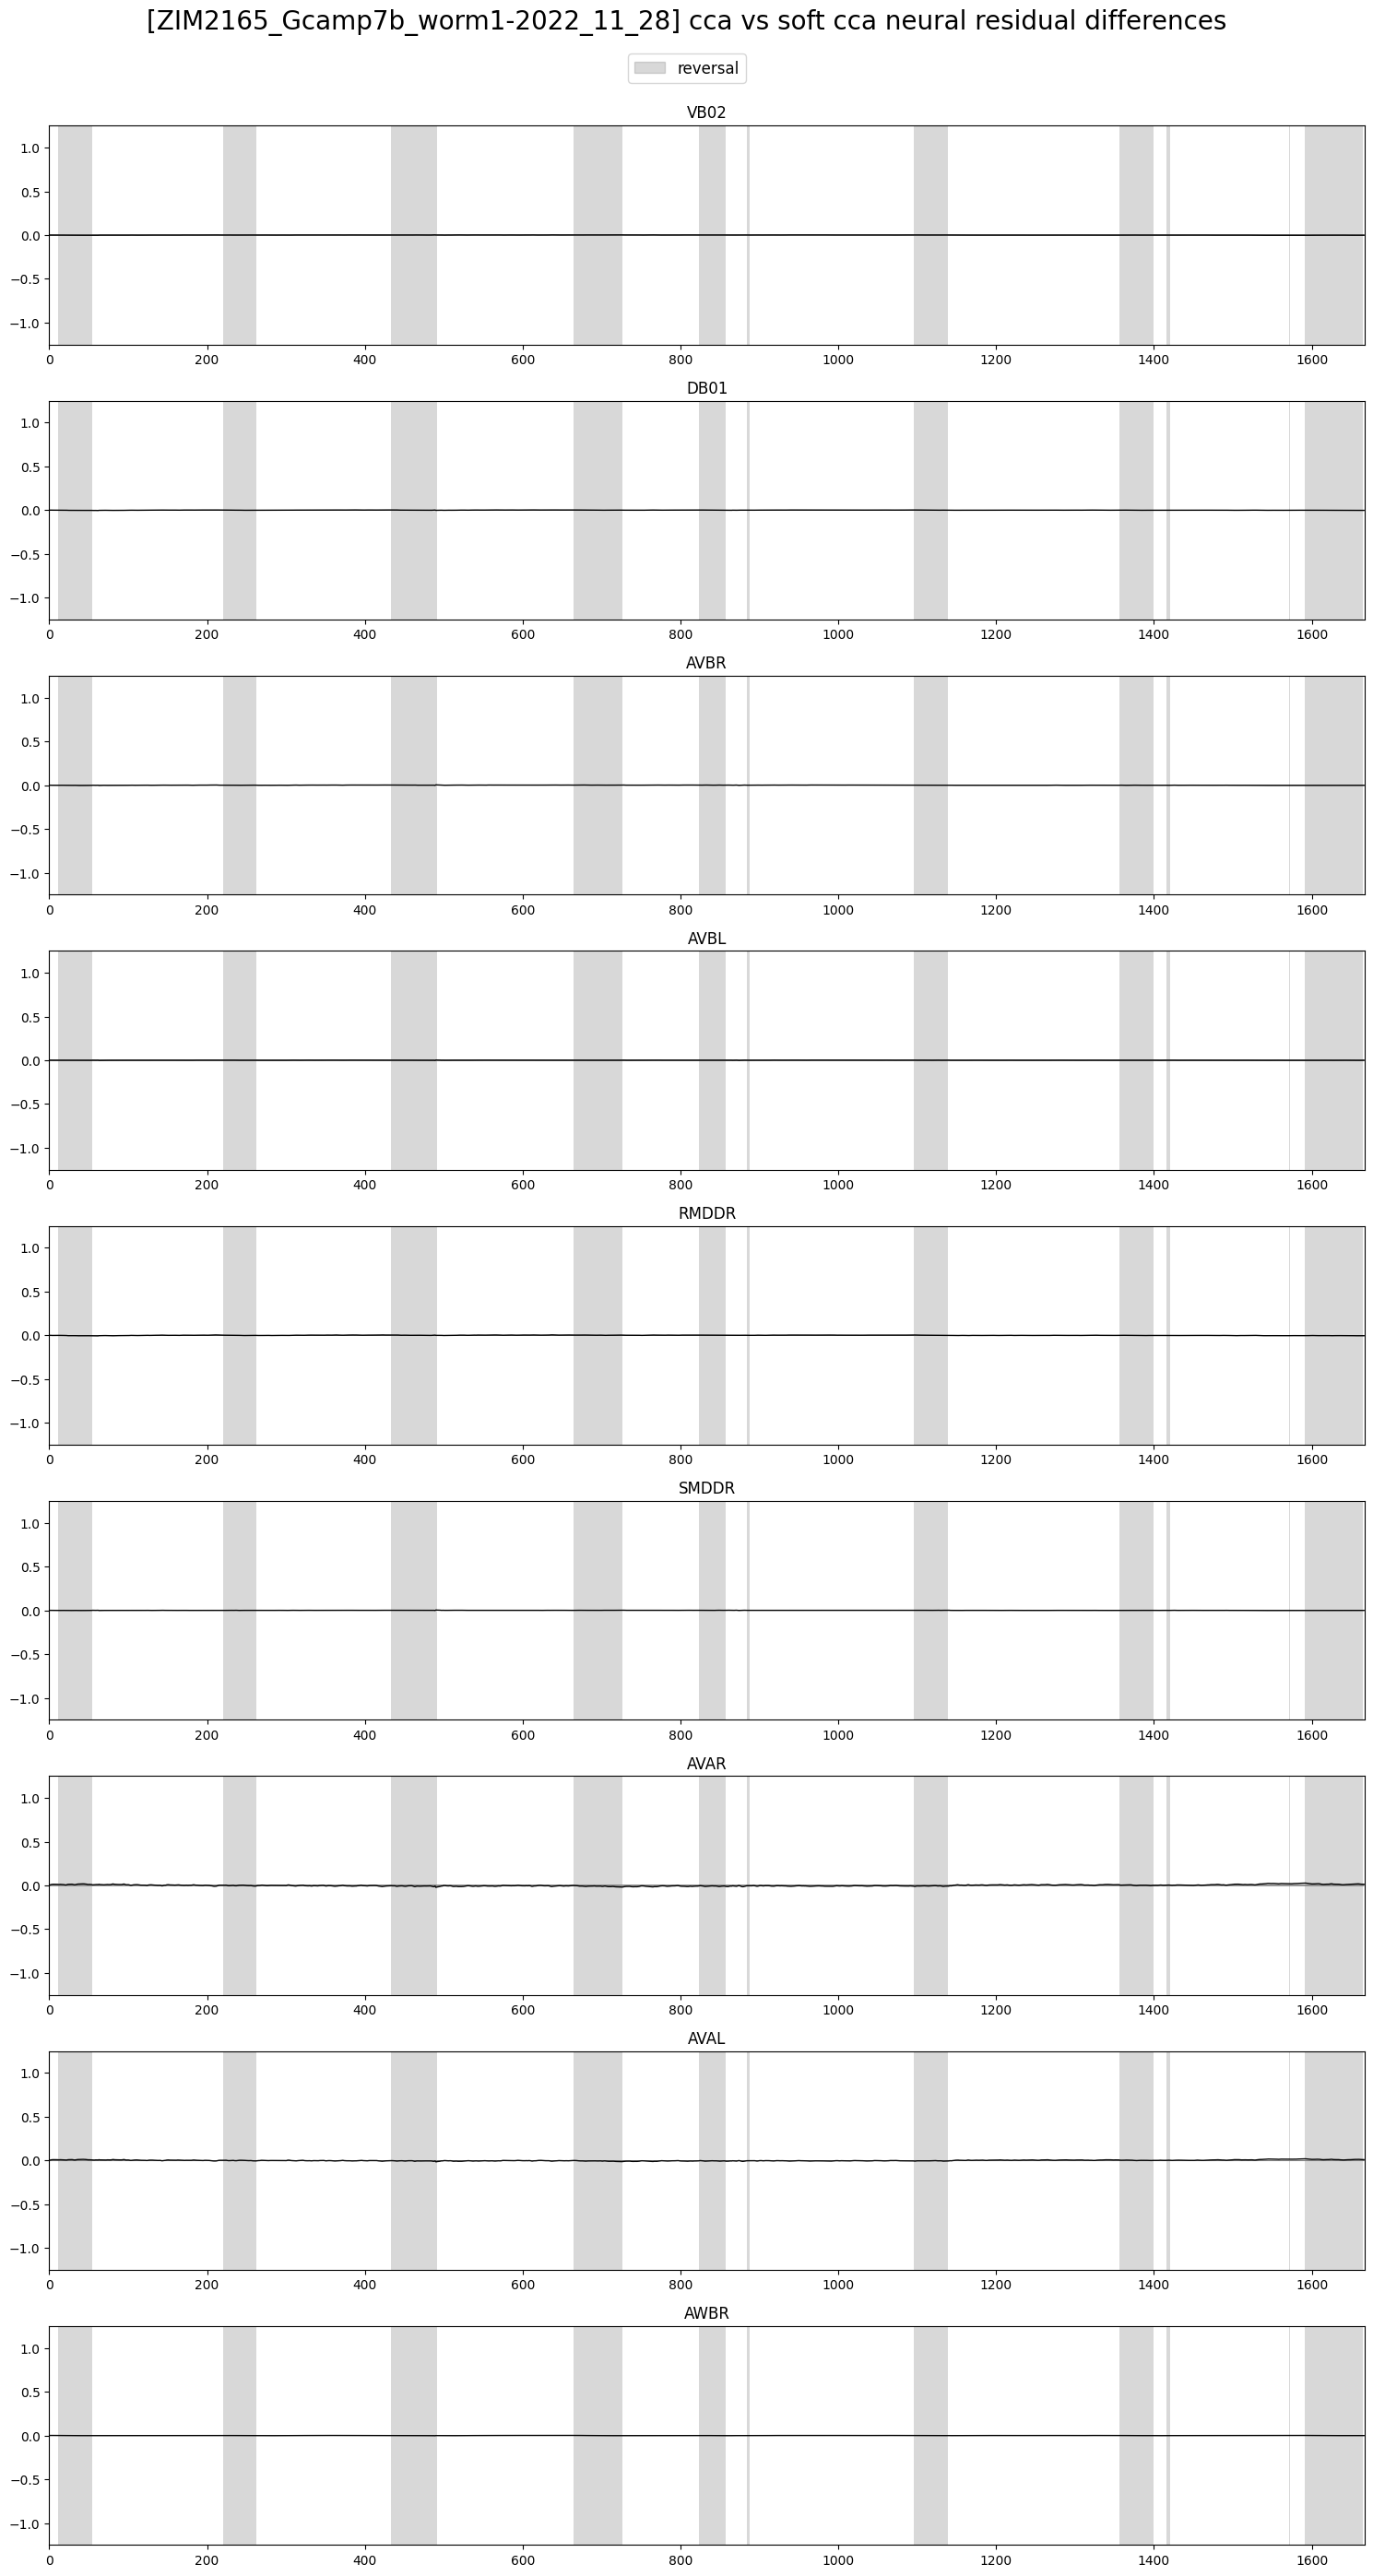

In [210]:
plot_utils.plot_traces([X_res_h_df[selection_n] - X_res_s_df[selection_n]],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] pca vs soft pca neural residual differences', ylimits=(-1.25, 1.25))